In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import sys
from pathlib import Path
from scipy import stats
from statsmodels.tsa.holtwinters import ExponentialSmoothing

# Setup
def find_project_root(start: Path) -> Path:
    for p in [start, *start.parents]:
        if (p / "src" / "config.py").exists():
            return p
    raise FileNotFoundError("Could not find project root")

PROJECT_ROOT = find_project_root(Path.cwd())
sys.path.insert(0, str(PROJECT_ROOT / "src"))
from config import PROCESSED_DATA_DIR, IMAGES_DIR

sns.set_style("whitegrid")
df = pd.read_csv(PROCESSED_DATA_DIR / "clean_online_retail.csv", parse_dates=['invoice_date'])
print("Data Loaded.")

Data Loaded.


C:\Users\adebi\AppData\Local\Temp\ipykernel_17080\4033944810.py:11: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=funnel_stages, y=funnel_counts, palette="Blues_d")


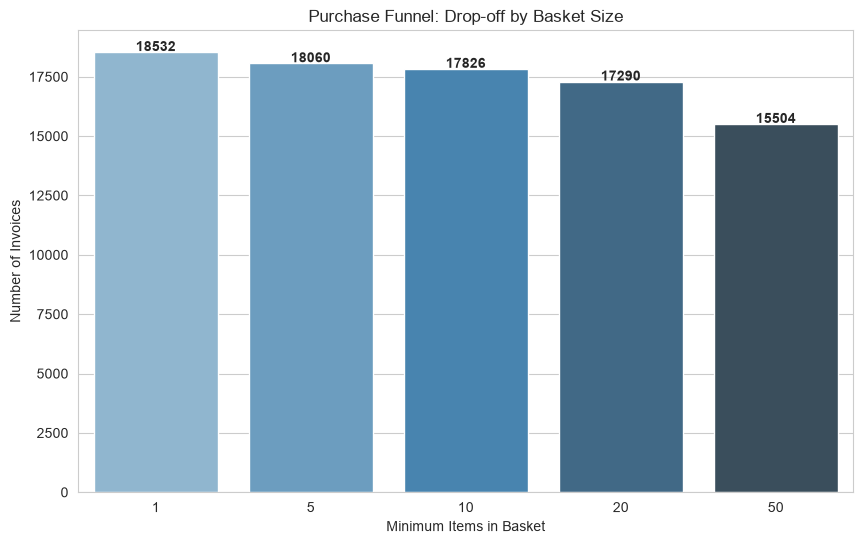

In [2]:
# 1. Calculate items per invoice (Basket Size)
basket_sizes = df.groupby('invoice')['quantity'].sum().reset_index()
basket_sizes.columns = ['invoice', 'total_items']

# 2. Define Funnel Stages (Bought at least 1, 5, 10, 20, 50 items)
funnel_stages = [1, 5, 10, 20, 50]
funnel_counts = [len(basket_sizes[basket_sizes['total_items'] >= stage]) for stage in funnel_stages]

# 3. Visualize Funnel
plt.figure(figsize=(10, 6))
sns.barplot(x=funnel_stages, y=funnel_counts, palette="Blues_d")
plt.title("Purchase Funnel: Drop-off by Basket Size")
plt.xlabel("Minimum Items in Basket")
plt.ylabel("Number of Invoices")
for i, v in enumerate(funnel_counts):
    plt.text(i, v + 50, str(v), ha='center', fontweight='bold')
plt.savefig(IMAGES_DIR / "basket_funnel.png", dpi=150)
plt.show()

In [3]:
# 1. Get average order value per invoice
invoice_values = df.groupby(['invoice', 'country'])['total_spend'].sum().reset_index()

# 2. Split into Group A (UK) and Group B (International)
uk_orders = invoice_values[invoice_values['country'] == 'United Kingdom']['total_spend']
intl_orders = invoice_values[invoice_values['country'] != 'United Kingdom']['total_spend']

print(f"UK Orders: {len(uk_orders)} | Mean: £{uk_orders.mean():.2f}")
print(f"Intl Orders: {len(intl_orders)} | Mean: £{intl_orders.mean():.2f}")

# 3. Run Independent T-Test
t_stat, p_value = stats.ttest_ind(uk_orders, intl_orders, equal_var=False)

print(f"\nT-statistic: {t_stat:.4f}")
print(f"P-value: {p_value:.6f}")

if p_value < 0.05:
    print("Result: Statistically Significant. Reject the Null Hypothesis.")
else:
    print("Result: Not Statistically Significant. Fail to reject the Null Hypothesis.")

UK Orders: 16646 | Mean: £439.05
Intl Orders: 1886 | Mean: £849.97

T-statistic: -9.6589
P-value: 0.000000
Result: Statistically Significant. Reject the Null Hypothesis.


Next 3 Months Revenue Forecast:
2012-01-31    £925,546.85
2012-02-29    £959,606.10
2012-03-31    £993,665.35
Freq: ME, dtype: str


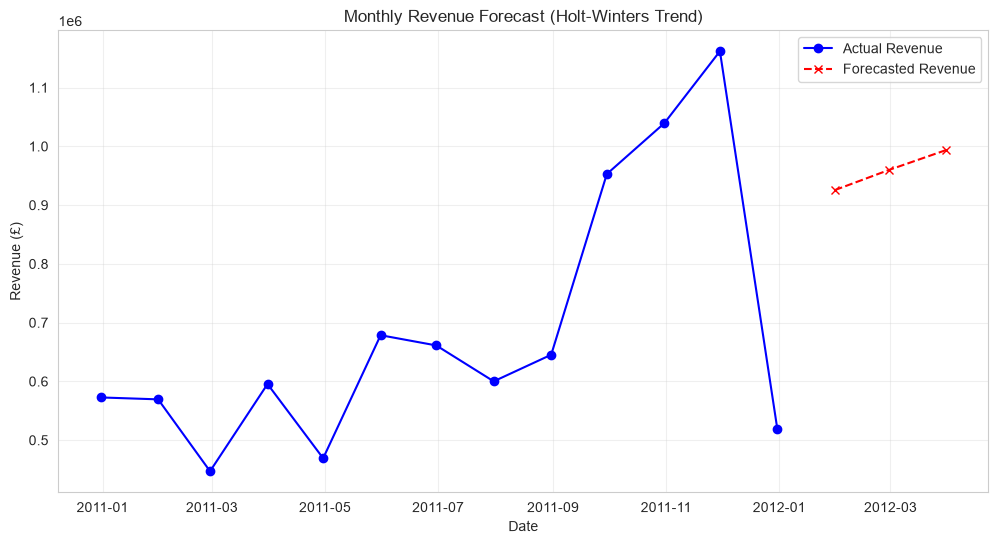

In [7]:
# ============================================
# TIME-SERIES FORECASTING (Holt-Winters Trend)
# ============================================
import matplotlib.pyplot as plt
from statsmodels.tsa.holtwinters import ExponentialSmoothing

# 1. Aggregate revenue by month
# Note: In pandas 3.0, 'M' is deprecated for month-end. We use 'ME'.
monthly_revenue = df.set_index('invoice_date')['total_spend'].resample('ME').sum()

# 2. Fit Holt-Winters Forecasting Model (Trend only)
# We exclude seasonality because the dataset only has ~13 months, 
# and seasonality requires at least 24 months (2 full cycles) to calculate.
model = ExponentialSmoothing(
    monthly_revenue, 
    trend='add'
).fit()

# 3. Forecast the next 3 months
forecast = model.forecast(3)

print("Next 3 Months Revenue Forecast:")
print(forecast.apply(lambda x: f"£{x:,.2f}"))

# 4. Plot the Actual vs Forecasted Revenue
plt.figure(figsize=(12, 6))
plt.plot(monthly_revenue.index, monthly_revenue.values, marker='o', label='Actual Revenue', color='blue')
plt.plot(forecast.index, forecast.values, marker='x', linestyle='--', color='red', label='Forecasted Revenue')

plt.title("Monthly Revenue Forecast (Holt-Winters Trend)")
plt.ylabel("Revenue (£)")
plt.xlabel("Date")
plt.legend()
plt.grid(True, alpha=0.3)

# Save the chart for GitHub
plt.savefig(IMAGES_DIR / "revenue_forecast.png", dpi=150, bbox_inches='tight')
plt.show()